In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import os
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
import warnings
warnings.filterwarnings('ignore')

In [2]:
train_path = r'C:\Users\mathe\Downloads\titanic\train.csv' #r is there so python understands that its not code and it is a character - must for all file locations
test_path = r'C:\Users\mathe\Downloads\titanic\test.csv'
df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)
df_train.head() , df_test.head()

(   PassengerId  Survived  Pclass  \
 0            1         0       3   
 1            2         1       1   
 2            3         1       3   
 3            4         1       1   
 4            5         0       3   
 
                                                 Name     Sex   Age  SibSp  \
 0                            Braund, Mr. Owen Harris    male  22.0      1   
 1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
 2                             Heikkinen, Miss. Laina  female  26.0      0   
 3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
 4                           Allen, Mr. William Henry    male  35.0      0   
 
    Parch            Ticket     Fare Cabin Embarked  
 0      0         A/5 21171   7.2500   NaN        S  
 1      0          PC 17599  71.2833   C85        C  
 2      0  STON/O2. 3101282   7.9250   NaN        S  
 3      0            113803  53.1000  C123        S  
 4      0            373450   8.0500

In [6]:
from sklearn.model_selection import train_test_split
#11 features
X = df_train.drop(columns=['Survived'])
y = df_train['Survived']

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape, X_val.shape)
print(y_train.mean(), y_val.mean())


(712, 11) (179, 11)
0.38342696629213485 0.3854748603351955


In [7]:
pip install xgboost


   ---------------------------------------- 0.0/72.0 MB ? eta -:--:--
   --- ------------------------------------ 5.8/72.0 MB 29.3 MB/s eta 0:00:03
   --- ------------------------------------ 7.1/72.0 MB 18.2 MB/s eta 0:00:04
   ---- ----------------------------------- 7.6/72.0 MB 13.0 MB/s eta 0:00:05
   ---- ----------------------------------- 7.6/72.0 MB 13.0 MB/s eta 0:00:05
   ---- ----------------------------------- 7.9/72.0 MB 8.1 MB/s eta 0:00:08
   ---- ----------------------------------- 8.1/72.0 MB 7.0 MB/s eta 0:00:10
   ---- ----------------------------------- 8.4/72.0 MB 6.3 MB/s eta 0:00:11
   ---- ----------------------------------- 8.9/72.0 MB 5.4 MB/s eta 0:00:12
   ----- ---------------------------------- 9.2/72.0 MB 5.2 MB/s eta 0:00:13
   ----- ---------------------------------- 9.4/72.0 MB 4.7 MB/s eta 0:00:14
   ----- ---------------------------------- 9.4/72.0 MB 4.7 MB/s eta 0:00:14
   ----- ---------------------------------- 9.7/72.0 MB 4.1 MB/s eta 0:00:16
  


[notice] A new release of pip is available: 25.0.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
import xgboost as xgb
from sklearn.metrics import accuracy_score, roc_auc_score


In [15]:
print(X_train.dtypes)


PassengerId      int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


In [16]:
numeric_features = [
    'Age',
    'Fare',
    'SibSp',
    'Parch'
]

categorical_features = [
    'Sex',
    'Embarked',
    'Pclass'
]


In [30]:
#handling objects and NaNs

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)
X_train_enc = preprocessor.fit_transform(X_train)
X_val_enc = preprocessor.transform(X_val)
print(X_train_enc.shape)
print(X_val_enc.shape)


print(type(X_train_enc))
print(X_train_enc.shape)
print(np.isnan(X_train_enc).sum())




(712, 12)
(179, 12)
<class 'numpy.ndarray'>
(712, 12)
0


In [31]:
#XGBoost Model
xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42
)

#Train and Evaluate
xgb_model.fit(X_train_enc, y_train)
y_val_pred = xgb_model.predict(X_val_enc)
y_val_proba = xgb_model.predict_proba(X_val_enc)[:, 1]

acc = accuracy_score(y_val, y_val_pred)
auc = roc_auc_score(y_val, y_val_proba)

print(f"Validation Accuracy: {acc:.4f}")
print(f"Validation AUC: {auc:.4f}")

Validation Accuracy: 0.7989
Validation AUC: 0.8097


In [34]:
#test set testing
X_test = df_test.copy()
X_test_enc = preprocessor.transform(X_test)
test_preds = xgb_model.predict(X_test_enc)
test_proba = xgb_model.predict_proba(X_test_enc)[:, 1]

test_results = df_test.copy()

test_results['PredictedSurvived'] = test_preds
test_results['SurvivalProbability'] = test_proba

test_results.head()
test_results['SurvivalProbability'].describe()


count    418.000000
mean       0.384416
std        0.344205
min        0.011574
25%        0.096462
50%        0.210842
75%        0.790918
max        0.995385
Name: SurvivalProbability, dtype: float64

In [36]:
test_results[['PredictedSurvived', 'SurvivalProbability']].head(10)


,PredictedSurvived,SurvivalProbability
0,0,0.092069
1,0,0.059979
2,0,0.035974
3,0,0.075130
4,0,0.376526
5,0,0.123924
6,1,0.713163
7,0,0.069428
8,1,0.857941
9,0,0.063371


In [37]:
test_results.sort_values('SurvivalProbability', ascending=False).head(10)
test_results.sort_values('SurvivalProbability').head(10)


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,PredictedSurvived,SurvivalProbability
211,1103,3,"Finoli, Mr. Luigi",male,NaN,0,0,SOTON/O.Q. 3101308,7.0500,NaN,S,0,0.011574
163,1055,3,"Pearce, Mr. Ernest",male,NaN,0,0,343271,7.0000,NaN,S,0,0.011574
152,1044,3,"Storey, Mr. Thomas",male,60.5,0,0,3701,NaN,NaN,S,0,0.015616
232,1124,3,"Wiklund, Mr. Karl Johan",male,21.0,1,0,3101266,6.4958,NaN,S,0,0.016442
325,1217,3,"Assam, Mr. Ali",male,23.0,0,0,SOTON/O.Q. 3101309,7.0500,NaN,S,0,0.018864
21,913,3,"Olsen, Master. Artur Karl",male,9.0,0,1,C 17368,3.1708,NaN,S,0,0.021337
266,1158,1,"Chisholm, Mr. Roderick Robert Crispin",male,NaN,0,0,112051,0.0000,NaN,S,0,0.024271
372,1264,1,"Ismay, Mr. Joseph Bruce",male,49.0,0,0,112058,0.0000,B52 B54 B56,S,0,0.025251
116,1008,3,"Thomas, Mr. John",male,NaN,0,0,2681,6.4375,NaN,C,0,0.027412
13,905,2,"Howard, Mr. Benjamin",male,63.0,1,0,24065,26.0000,NaN,S,0,0.029287


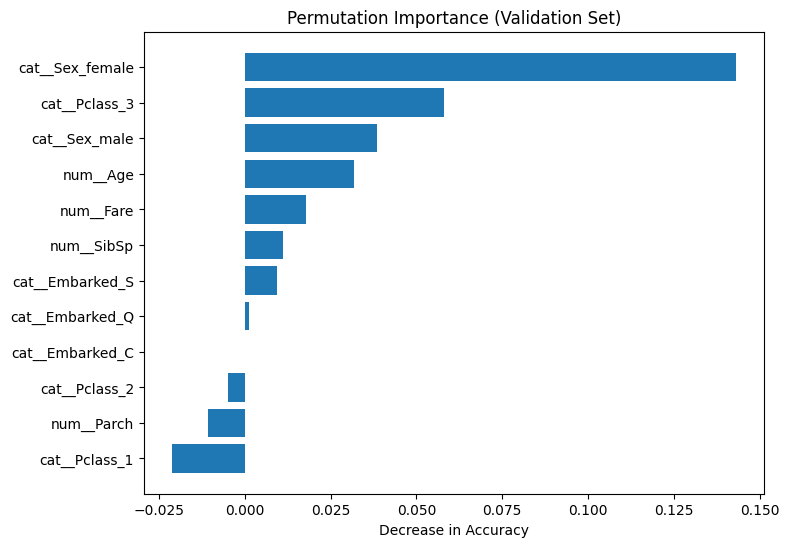

In [43]:
from sklearn.inspection import permutation_importance

feature_names = preprocessor.get_feature_names_out()
X_train_enc = pd.DataFrame(
    X_train_enc,
    columns=feature_names,
    index=X_train.index
)

X_val_enc = pd.DataFrame(
    X_val_enc,
    columns=feature_names,
    index=X_val.index
)

#permutation importance to see which feature is the best
perm = permutation_importance(
    xgb_model,
    X_val_enc,
    y_val,
    n_repeats=10,
    random_state=42,
    scoring='accuracy'
)
perm_df = pd.DataFrame({
    'feature': X_train_enc.columns,
    'importance': perm.importances_mean
}).sort_values('importance', ascending=False)
perm_df.head(15)

plt.figure(figsize=(8, 6))
plt.barh(
    perm_df.head(top_n)['feature'][::-1],
    perm_df.head(top_n)['importance'][::-1]
)
plt.xlabel('Decrease in Accuracy')
plt.title('Permutation Importance (Validation Set)')
plt.show()

